# **DATASET LOADING**

In [ ]:
import pandas as pd
df = pd.read_excel("/content/solar_weather - Raw - Assignment Oct 2025-1.xlsx")
df.head()

,Time,Energy Captured[Wh],Sun Light Intensity (W/m2),Temperature,1 Hour Rain Fall,Cloud Coverage,Length of Day_Light
0,2017-01-01 00:00:00,0,0,1.6,0,100,450
1,2017-01-01 00:15:00,0,0,1.6,0,100,450
2,2017-01-01 00:30:00,0,0,1.6,0,100,450
3,2017-01-01 00:45:00,0,0,1.6,0,100,450
4,2017-01-01 01:00:00,0,0,1.7,0,100,450


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 196777 entries, 0 to 196776
Data columns (total 7 columns):
 #   Column                      Non-Null Count   Dtype 
---  ------                      --------------   ----- 
 0   Time                        196777 non-null  object
 1   Energy Captured[Wh]         196777 non-null  object
 2   Sun Light Intensity (W/m2)  196777 non-null  object
 3   Temperature                 196777 non-null  object
 4   1 Hour Rain Fall            196777 non-null  object
 5   Cloud Coverage              196777 non-null  object
 6   Length of Day_Light         196777 non-null  object
dtypes: object(7)
memory usage: 10.5+ MB


# **Task 1: Exploratory Data Analysis (EDA)**

## a) Descriptive Statistics

In [ ]:
df['Time'] = pd.to_datetime(df['Time'])

# Convert other relevant columns to numeric, coercing errors to NaN
num_cols = ['Energy Captured[Wh]','Sun Light Intensity (W/m2)','Temperature','1 Hour Rain Fall','Cloud Coverage',
                'Length of Day_Light']
for col in num_cols:
    df[col] = pd.to_numeric(df[col], errors='coerce')

# Now, perform descriptive statistics on the numeric columns
print(df.describe())
print(df.median(numeric_only=True))
print(df.mode().iloc[0])

                                Time  Energy Captured[Wh]  \
count                         196769        196773.000000   
mean   2019-10-29 23:36:25.935792128           573.011262   
min              2017-01-01 00:00:00           -54.000000   
25%              2018-06-02 11:45:00             0.000000   
50%              2019-10-28 21:45:00             0.000000   
75%              2021-03-24 07:45:00           577.000000   
max              2022-08-31 17:45:00          5020.000000   
std                              NaN          1044.832388   

       Sun Light Intensity (W/m2)    Temperature  1 Hour Rain Fall  \
count               196770.000000  196771.000000     196773.000000   
mean                    32.598451       9.790703          0.066036   
min                      0.000000     -16.600000          0.000000   
25%                      0.000000       3.600000          0.000000   
50%                      1.600000       9.300000          0.000000   
75%                     46.800

## b) Correlation Heatmaps

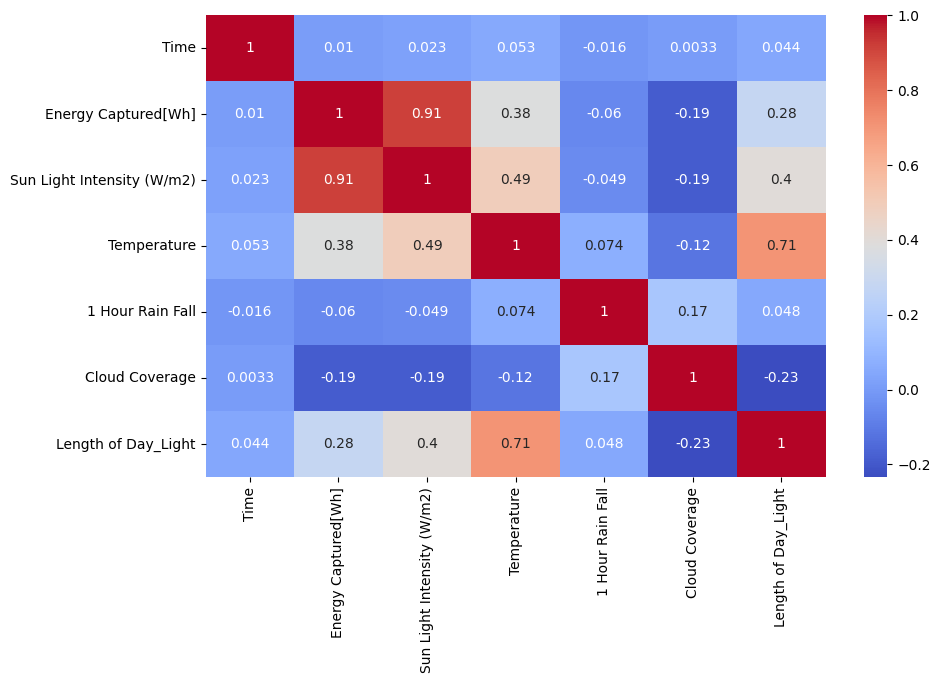

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

## c) Frequency Distribution Charts

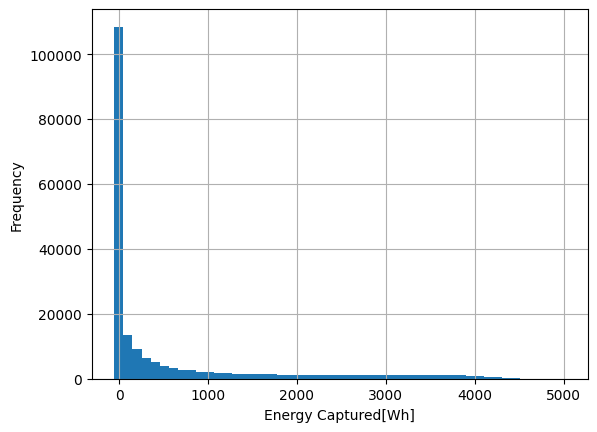

In [ ]:
df['Energy Captured[Wh]'].hist(bins=50)
plt.xlabel("Energy Captured[Wh]")
plt.ylabel("Frequency")
plt.show()

# **Task 2: Data Preprocessing and Feature Engineering**

# Data Processing

In [ ]:
# [A] Missing values
df.isnull().sum()

,0
Time,8
Energy Captured[Wh],4
Sun Light Intensity (W/m2),7
Temperature,6
1 Hour Rain Fall,4
Cloud Coverage,13
Length of Day_Light,5


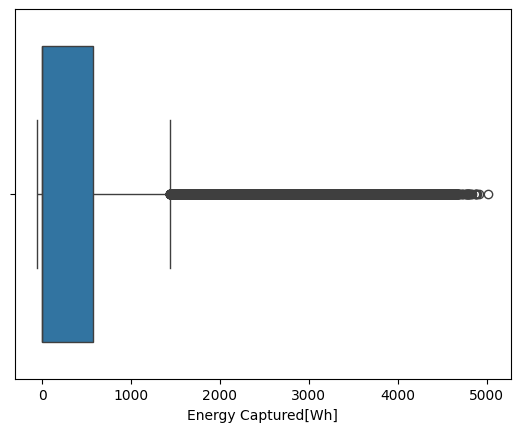

In [ ]:
# [B] Outliers
sns.boxplot(x=df['Energy Captured[Wh]'])
plt.show()

In [ ]:
# Handling the Issue
df.fillna(method="ffill", inplace=True)

/tmp/ipython-input-3742854141.py:2: FutureWarning: DataFrame.fillna with 'method' is deprecated and will raise in a future version. Use obj.ffill() or obj.bfill() instead.
  df.fillna(method="ffill", inplace=True)


# Feature Engineering

In [ ]:
# Extract useful features from time.
df['Time'] = pd.to_datetime(df['Time'])
df['Hour'] = df['Time'].dt.hour
df['Month'] = df['Time'].dt.month
df['Year'] = df['Time'].dt.year

# **Task 3: Model Development and Evaluation**

# 1. Correlation Heatmaps

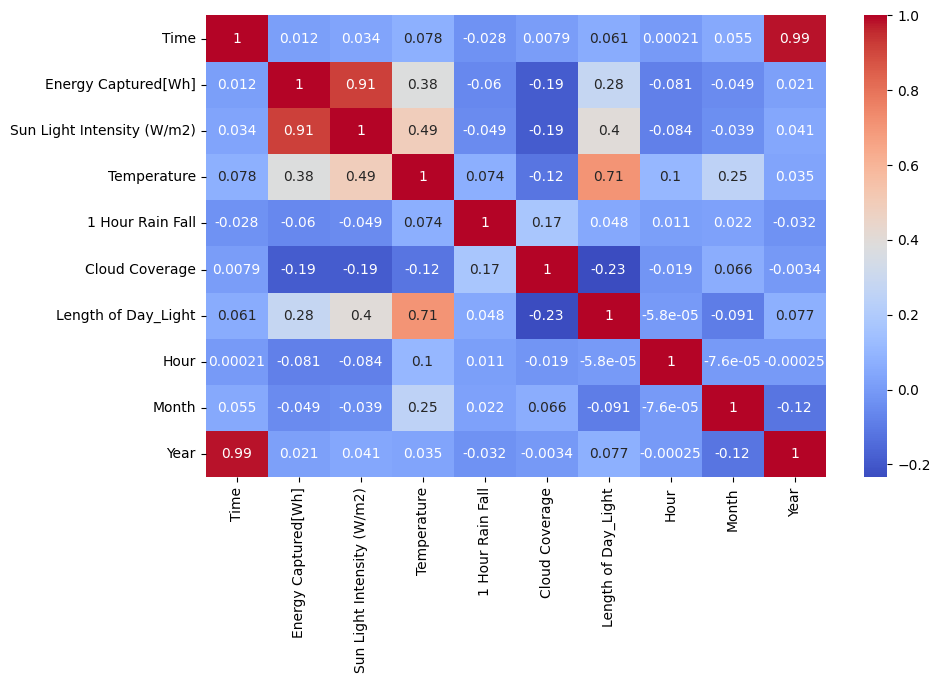

In [ ]:
import seaborn as sns
import matplotlib.pyplot as plt
plt.figure(figsize=(10,6))
sns.heatmap(df.corr(), annot=True, cmap="coolwarm")
plt.show()

# 2. Train–test split

In [ ]:
from sklearn.model_selection import train_test_split

X = df.drop(columns=['Energy Captured[Wh]', 'Time'])
Y = df['Energy Captured[Wh]']

train_X,test_X,train_Y,test_Y = train_test_split(X,Y,test_size=0.2,shuffle=False)

# a) Linear Regression Model

In [ ]:
from sklearn.linear_model import LinearRegression
lr = LinearRegression()
lr.fit(train_X,train_Y)
y_pred_lr = lr.predict(test_X)

# b) Random Forest Regressor

In [ ]:
from sklearn.ensemble import RandomForestRegressor
rfr = RandomForestRegressor(n_estimators=100, random_state=42)
rfr.fit(train_X,train_Y)
Y_pred_rfr = rfr.predict(test_X)

# **Model Evaluation**

In [ ]:
from sklearn.metrics import r2_score, mean_absolute_error, mean_squared_error

def evaluate(y_true, y_pred):
    return {
        "R2": r2_score(y_true, y_pred),
        "MAE": mean_absolute_error(y_true, y_pred),
        "MSE": mean_squared_error(y_true, y_pred)
    }

evaluate(test_Y, y_pred_lr)
evaluate(test_Y, Y_pred_rfr)

{'R2': 0.8991460760368201, 'MAE': 138.14192706234698, 'MSE': 110462.5433869956}

# Comparing Two Models

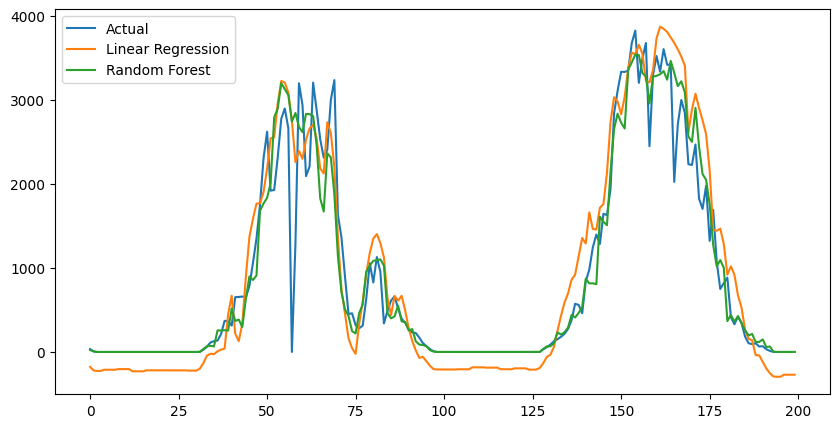

In [ ]:
plt.figure(figsize=(10,5))
plt.plot(test_Y.values[:200], label="Actual")
plt.plot(y_pred_lr[:200], label="Linear Regression")
plt.plot(Y_pred_rfr[:200], label="Random Forest")
plt.legend()
plt.show()

# **Task 4: Using your Models for and Business Recommendations and Forecasts**

# Use historical January averages



In [ ]:
# Convert timestamp and extract year & month
df['Time'] = pd.to_datetime(df['Time'])
df['Year'] = df['Time'].dt.year
df['Month'] = df['Time'].dt.month

# Filter January data
jan_data = df[df['Month'] == 1]

# Calculate average Energy Production for each previous year
pvs_years_enrgy = (
    jan_data
    .groupby('Year')['Energy Captured[Wh]']
    .mean()
    .reset_index()
)

pvs_years_enrgy

,Year,Energy Captured[Wh]
0,2017,179.729275
1,2018,125.431452
2,2019,117.248992
3,2020,122.447245
4,2021,83.167339
5,2022,161.141204


# Predict January 2026

In [ ]:
# Take average of January feature values
jan_features_avg = jan_data.drop(
    columns=['Energy Captured[Wh]', 'Time']
).mean()

# Convert to DataFrame
jan_2026_input = pd.DataFrame([jan_features_avg])

# Update year to 2026
jan_2026_input['Year'] = 2026

# Predict
jan_2026_predict = rfr.predict(jan_2026_input)[0]
print(jan_2026_predict)

179.91666666666669


In [ ]:
jan_2026_row = pd.DataFrame({
    'Year': [2026],
    'Energy Capture': [jan_2026_predict]
})

comparison_table = pd.concat([pvs_years_enrgy, jan_2026_row], ignore_index=True)
comparison_table

,Year,Energy Captured[Wh],Energy Capture
0,2017,179.729275,NaN
1,2018,125.431452,NaN
2,2019,117.248992,NaN
3,2020,122.447245,NaN
4,2021,83.167339,NaN
5,2022,161.141204,NaN
6,2026,NaN,179.916667
